Język: [English](examples.en.ipynb) | **Polski**

# Wykład 03. Backpropagation, reguła łańcuchowa i autograd

Notebook uzupełnia [`lecture.md`](lecture.md). Ten sam gradient jest obliczany
analitycznie, przez `autograd` oraz za pomocą różnic skończonych. Porównanie
zaczyna się od jednego neuronu, a następnie obejmuje sieć z warstwą ukrytą i
cały batch. Dalsze eksperymenty dotyczą akumulacji gradientów, `detach()` oraz
zanikania gradientu w głębokich stosach warstw.


In [1]:
import matplotlib.pyplot as plt
import torch

torch.manual_seed(0)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Używane urządzenie: {device}")

Używane urządzenie: cpu


## 1. Graf skalarny. Trzy metody

Przykład wykorzystuje neuron z aktywacją sigmoid i stratą MSE, gdzie $u=wx$,
$v=u+b$, $a=\sigma(v)$ oraz $L=(a-t)^2$. Wartości odpowiadają przykładowi
rozwiązanemu na wykładzie.

```mermaid
flowchart LR
    w --> u["u = w·x"]
    x --> u
    u --> v["v = u + b"]
    b --> v
    v --> a["a = σ(v)"]
    a --> L["L = (a - t)²"]
    t --> L
```


In [2]:
x_val, w_val, b_val, t_val = 1.5, 0.8, -0.3, 1.0


def forward_scalar(w, b, x, t):
    u = w * x
    v = u + b
    a = torch.sigmoid(v)
    loss = (a - t) ** 2
    return u, v, a, loss


x = torch.tensor(x_val)
t = torch.tensor(t_val)

# --- metoda 1: wzor reczny ---
w = torch.tensor(w_val)
b = torch.tensor(b_val)
u, v, a, loss = forward_scalar(w, b, x, t)
delta_v = 2 * (a - t) * (a * (1 - a))  # dL/dv = dL/da * da/dv
grad_w_manual = (delta_v * x).item()
grad_b_manual = delta_v.item()

# --- metoda 2: autograd ---
w_ag = torch.tensor(w_val, requires_grad=True)
b_ag = torch.tensor(b_val, requires_grad=True)
_, _, _, loss_ag = forward_scalar(w_ag, b_ag, x, t)
loss_ag.backward()
grad_w_autograd = w_ag.grad.item()
grad_b_autograd = b_ag.grad.item()


# --- metoda 3: roznice skonczone (centralne) ---
def loss_of(w_, b_):
    return forward_scalar(torch.tensor(w_), torch.tensor(b_), x, t)[3].item()


h = 1e-4
grad_w_fd = (loss_of(w_val + h, b_val) - loss_of(w_val - h, b_val)) / (2 * h)
grad_b_fd = (loss_of(w_val, b_val + h) - loss_of(w_val, b_val - h)) / (2 * h)

print(f"u={u.item():.4f}  v={v.item():.4f}  a={a.item():.4f}  L={loss.item():.4f}")
print()
print(f"{'metoda':12s}{'dL/dw':>12s}{'dL/db':>12s}")
print(f"{'reczna':12s}{grad_w_manual:12.6f}{grad_b_manual:12.6f}")
print(f"{'autograd':12s}{grad_w_autograd:12.6f}{grad_b_autograd:12.6f}")
print(f"{'rozn. skon.':12s}{grad_w_fd:12.6f}{grad_b_fd:12.6f}  (h={h})")

assert abs(grad_w_manual - grad_w_autograd) < 1e-6
assert abs(grad_b_manual - grad_b_autograd) < 1e-6
print("\nOK: wzor reczny i autograd zgadzaja sie praktycznie co do bitu.")

u=1.2000  v=0.9000  a=0.7109  L=0.0836

metoda             dL/dw       dL/db
reczna         -0.178200   -0.118800
autograd       -0.178200   -0.118800
rozn. skon.    -0.178181   -0.118874  (h=0.0001)

OK: wzor reczny i autograd zgadzaja sie praktycznie co do bitu.


## 2. Wpływ kroku $h$ na różnice skończone

Gradient $\partial L/\partial w$ jest obliczany różnicami skończonymi dla
wielu wartości $h$. Typ `float64` pozwala oddzielić błąd metody od
ograniczonej precyzji `float32`.


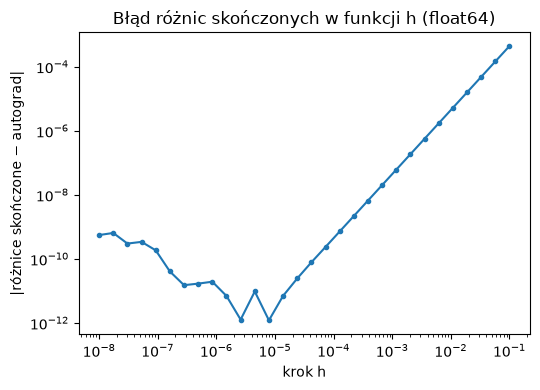

najlepsze h w tym przebiegu: 7.9e-06  blad=1.21e-12
dla duzego h=1.0e-01: blad=4.43e-04  (dominuje blad obciecia)
dla malego h=1.0e-08: blad=5.55e-10  (dominuje blad zaokraglen)


In [3]:
w64 = torch.tensor(w_val, dtype=torch.float64)
b64 = torch.tensor(b_val, dtype=torch.float64)
x64 = torch.tensor(x_val, dtype=torch.float64)
t64 = torch.tensor(t_val, dtype=torch.float64)

w64_ag = w64.clone().requires_grad_(True)
_, _, _, loss64_ag = forward_scalar(w64_ag, b64, x64, t64)
loss64_ag.backward()
grad_w_autograd64 = w64_ag.grad.item()


def loss_of64(w_):
    return forward_scalar(torch.tensor(w_, dtype=torch.float64), b64, x64, t64)[3].item()


hs = torch.logspace(-8, -1, 30)
errors = []
for h_ in hs:
    h_ = h_.item()
    fd = (loss_of64(w_val + h_) - loss_of64(w_val - h_)) / (2 * h_)
    errors.append(abs(fd - grad_w_autograd64))

plt.figure(figsize=(5.5, 4))
plt.loglog(hs, errors, marker="o", markersize=3)
plt.xlabel("krok h")
plt.ylabel("|różnice skończone − autograd|")
plt.title("Błąd różnic skończonych w funkcji h (float64)")
plt.tight_layout()
plt.show()

best_idx = min(range(len(errors)), key=lambda i: errors[i])
print(f"najlepsze h w tym przebiegu: {hs[best_idx].item():.1e}  blad={errors[best_idx]:.2e}")
print(f"dla duzego h={hs[-1].item():.1e}: blad={errors[-1]:.2e}  (dominuje blad obciecia)")
print(f"dla malego h={hs[0].item():.1e}: blad={errors[0]:.2e}  (dominuje blad zaokraglen)")

Krzywa ma kształt litery U. Dla dużego $h$ błąd rośnie, ponieważ przybliżenie
przestaje być lokalne. Jest to błąd obcięcia rzędu $h^2$. Przy bardzo małym
$h$ wartości $L(w+h)$ i $L(w-h)$ są na tyle bliskie, że odejmowanie prowadzi
do utraty cyfr znaczących. Ten błąd zaokrągleń ma rząd
$\varepsilon_{\text{maszyny}}/h$. Z tego powodu narzędzia takie jak
`torch.autograd.gradcheck` używają `float64` i starannie dobranego $h$.
Sprawdzanie gradientu jest przybliżeniem, a nie dowodem.


## 3. Sieć z jedną warstwą ukrytą. Trzy metody

Sieć ma 2 cechy wejściowe, 3 neurony ukryte z sigmoid i 1 wyjście liniowe.
Strata MSE jest uśredniana po batchu złożonym z $N=5$ przykładów.


In [4]:
N, n_in, m_hidden, k_out = 5, 2, 3, 1

X = torch.randn(N, n_in)
Y = torch.randn(N, k_out)

W1 = torch.randn(m_hidden, n_in) * 0.5
b1 = torch.randn(m_hidden) * 0.5
W2 = torch.randn(k_out, m_hidden) * 0.5
b2 = torch.randn(k_out) * 0.5


def forward_net(X, W1, b1, W2, b2, Y):
    Z1 = X @ W1.T + b1
    A1 = torch.sigmoid(Z1)
    Z2 = A1 @ W2.T + b2
    loss = torch.mean((Z2 - Y) ** 2)
    return Z1, A1, Z2, loss


# --- metoda 1: wzor reczny (batchowy) ---
Z1, A1, Z2, loss = forward_net(X, W1, b1, W2, b2, Y)

Delta2 = (2.0 / N) * (Z2 - Y)  # (N, k)
dW2_manual = Delta2.T @ A1  # (k, m)
db2_manual = Delta2.sum(dim=0)  # (k,)

dA1 = Delta2 @ W2  # (N, m)
Delta1 = dA1 * (A1 * (1 - A1))  # (N, m), Jacobian aktywacji diagonalny
dW1_manual = Delta1.T @ X  # (m, n_in)
db1_manual = Delta1.sum(dim=0)  # (m,)

print(
    "Ksztalty:  dW1",
    tuple(dW1_manual.shape),
    " db1",
    tuple(db1_manual.shape),
    " dW2",
    tuple(dW2_manual.shape),
    " db2",
    tuple(db2_manual.shape),
)
assert dW1_manual.shape == W1.shape
assert db1_manual.shape == b1.shape
assert dW2_manual.shape == W2.shape
assert db2_manual.shape == b2.shape
print("OK: ksztalty gradientow zgadzaja sie z ksztaltami parametrow.")

Ksztalty:  dW1 (3, 2)  db1 (3,)  dW2 (1, 3)  db2 (1,)
OK: ksztalty gradientow zgadzaja sie z ksztaltami parametrow.


In [5]:
# --- metoda 2: autograd ---
W1_ag = W1.clone().requires_grad_(True)
b1_ag = b1.clone().requires_grad_(True)
W2_ag = W2.clone().requires_grad_(True)
b2_ag = b2.clone().requires_grad_(True)

_, _, _, loss_ag = forward_net(X, W1_ag, b1_ag, W2_ag, b2_ag, Y)
loss_ag.backward()

max_diff_W1 = (dW1_manual - W1_ag.grad).abs().max().item()
max_diff_b1 = (db1_manual - b1_ag.grad).abs().max().item()
max_diff_W2 = (dW2_manual - W2_ag.grad).abs().max().item()
max_diff_b2 = (db2_manual - b2_ag.grad).abs().max().item()

print("max|reczny - autograd|:")
print(f"  W1={max_diff_W1:.2e}  b1={max_diff_b1:.2e}  W2={max_diff_W2:.2e}  b2={max_diff_b2:.2e}")
assert max(max_diff_W1, max_diff_b1, max_diff_W2, max_diff_b2) < 1e-5
print("OK: reczny batchowy backprop zgadza sie z autograd.")

max|reczny - autograd|:
  W1=1.49e-08  b1=7.45e-09  W2=0.00e+00  b2=0.00e+00
OK: reczny batchowy backprop zgadza sie z autograd.


In [6]:
# --- metoda 3: numeryczne gradient checking (float64, kilka wpisow) ---
X64, Y64 = X.double(), Y.double()
W1_64, b1_64, W2_64, b2_64 = W1.double(), b1.double(), W2.double(), b2.double()


def loss_with_params(W1_, b1_, W2_, b2_):
    return forward_net(X64, W1_, b1_, W2_, b2_, Y64)[3].item()


h = 1e-5
checks = [("W1", 0, 0), ("W1", 1, 1), ("W2", 0, 1), ("b1", 1, None), ("b2", 0, None)]
manual_values = {
    "W1": dW1_manual.double(),
    "b1": db1_manual.double(),
    "W2": dW2_manual.double(),
    "b2": db2_manual.double(),
}

for name, i, j in checks:
    Wp = {"W1": W1_64.clone(), "b1": b1_64.clone(), "W2": W2_64.clone(), "b2": b2_64.clone()}
    Wm = {"W1": W1_64.clone(), "b1": b1_64.clone(), "W2": W2_64.clone(), "b2": b2_64.clone()}
    if j is None:
        Wp[name][i] += h
        Wm[name][i] -= h
        manual_val = manual_values[name][i].item()
    else:
        Wp[name][i, j] += h
        Wm[name][i, j] -= h
        manual_val = manual_values[name][i, j].item()

    fd = (
        loss_with_params(Wp["W1"], Wp["b1"], Wp["W2"], Wp["b2"])
        - loss_with_params(Wm["W1"], Wm["b1"], Wm["W2"], Wm["b2"])
    ) / (2 * h)

    idx = f"[{i}]" if j is None else f"[{i},{j}]"
    diff = abs(manual_val - fd)
    print(f"{name}{idx:8s} reczny={manual_val: .6f}  rozn.skon.={fd: .6f}  |roznica|={diff:.2e}")
    assert abs(manual_val - fd) < 1e-6

print("\nOK: numeryczne gradient checking (float64) potwierdza gradienty dla sprawdzonych wpisow.")

W1[0,0]    reczny= 0.009068  rozn.skon.= 0.009068  |roznica|=7.67e-10
W1[1,1]    reczny=-0.167198  rozn.skon.=-0.167198  |roznica|=8.74e-09
W2[0,1]    reczny= 0.003049  rozn.skon.= 0.003049  |roznica|=3.37e-08
b1[1]      reczny=-0.047364  rozn.skon.=-0.047364  |roznica|=3.43e-09
b2[0]      reczny=-0.217204  rozn.skon.=-0.217204  |roznica|=5.58e-08

OK: numeryczne gradient checking (float64) potwierdza gradienty dla sprawdzonych wpisow.


## 4. Akumulacja gradientów

Dwa kolejne wywołania `backward()` odbywają się bez `zero_grad()` między nimi.


In [7]:
w_acc = torch.tensor(w_val, requires_grad=True)
b_acc = torch.tensor(b_val, requires_grad=True)

_, _, _, loss1 = forward_scalar(w_acc, b_acc, x, t)
loss1.backward()
grad_after_first = w_acc.grad.item()

_, _, _, loss2 = forward_scalar(w_acc, b_acc, x, t)
loss2.backward()
grad_after_second = w_acc.grad.item()

print(f"grad po 1. backward(): {grad_after_first:.6f}")
print(f"grad po 2. backward() BEZ zero_grad(): {grad_after_second:.6f}")
ratio_acc = grad_after_second / grad_after_first
print(f"stosunek: {ratio_acc:.2f}  (oczekiwane: 2.00 - gradienty sie zsumowaly)")
assert abs(grad_after_second - 2 * grad_after_first) < 1e-6

w_acc.grad.zero_()
_, _, _, loss3 = forward_scalar(w_acc, b_acc, x, t)
loss3.backward()
grad_after_zero_then_backward = w_acc.grad.item()
print(
    f"grad po zero_grad() + 3. backward(): {grad_after_zero_then_backward:.6f}"
    "  (z powrotem jak po 1.)"
)
assert abs(grad_after_zero_then_backward - grad_after_first) < 1e-6

grad po 1. backward(): -0.178200
grad po 2. backward() BEZ zero_grad(): -0.356400
stosunek: 2.00  (oczekiwane: 2.00 - gradienty sie zsumowaly)
grad po zero_grad() + 3. backward(): -0.178200  (z powrotem jak po 1.)


## 5. `detach()` i przerwanie grafu

Do `v` prowadzą dwie ścieżki. Pierwsza zaczyna się w `w` i przechodzi przez
`u = w·x`, a druga w niezależnym parametrze `c`. Po odcięciu pierwszej ścieżki
przez `.detach()` pozostała część grafu nadal wymaga gradientu dzięki `c`.
Wywołanie `backward()` działa poprawnie, ale `w.grad` pozostaje równe `None`,
ponieważ jedyna droga od `w` do straty została przerwana.


In [8]:
w_a = torch.tensor(w_val, requires_grad=True)
c_a = torch.tensor(b_val, requires_grad=True)

# bez detach: gradient plynie do obu, w i c
u_a = w_a * x
v_a = u_a + c_a
a_a = torch.sigmoid(v_a)
loss_a = (a_a - t) ** 2
loss_a.backward()
print(f"bez detach(): w.grad = {w_a.grad.item():.6f}   c.grad = {c_a.grad.item():.6f}")

w_b = torch.tensor(w_val, requires_grad=True)
c_b = torch.tensor(b_val, requires_grad=True)

# z detach: przecinamy sciezke od w, c nadal wymaga gradientu
u_b = w_b * x
v_b = u_b.detach() + c_b  # <- tutaj przecinamy sciezke od w_b
a_b = torch.sigmoid(v_b)
loss_b = (a_b - t) ** 2
loss_b.backward()
print(f"z detach():   w.grad = {w_b.grad}   c.grad = {c_b.grad.item():.6f}")
assert w_b.grad is None
assert c_b.grad is not None

bez detach(): w.grad = -0.178200   c.grad = -0.118800
z detach():   w.grad = None   c.grad = -0.118800


## 6. Nasycenie i zanikanie gradientu

Stos zawiera 10 warstw liniowych bez biasu, przedzielonych tą samą funkcją
aktywacji. W każdej warstwie losowe wagi mają tę samą skalę. Po jednym
wywołaniu `backward()` mierzona jest norma gradientu wag każdej warstwy.


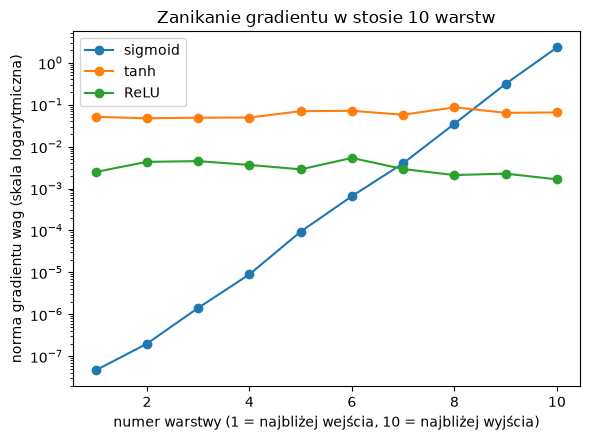

sigmoid  warstwa 1: 4.62e-08   warstwa 10: 2.31e+00  stosunek: 5.0e+07x
tanh     warstwa 1: 5.12e-02   warstwa 10: 6.52e-02  stosunek: 1.3e+00x
ReLU     warstwa 1: 2.48e-03   warstwa 10: 1.66e-03  stosunek: 6.7e-01x


In [9]:
import torch.nn as nn


def grad_norms_per_layer(activation_cls, depth=10, width=20, seed=0):
    torch.manual_seed(seed)
    layers = []
    for _ in range(depth):
        layers.append(nn.Linear(width, width, bias=False))
        layers.append(activation_cls())
    model = nn.Sequential(*layers)

    x_in = torch.randn(1, width)
    out = model(x_in)
    loss = out.sum()
    loss.backward()

    norms = [layer.weight.grad.norm().item() for layer in model if isinstance(layer, nn.Linear)]
    return norms  # norms[0] = warstwa najblizej wejscia, norms[-1] = najblizej wyjscia


depth = 10
results = {
    "sigmoid": grad_norms_per_layer(nn.Sigmoid, depth=depth),
    "tanh": grad_norms_per_layer(nn.Tanh, depth=depth),
    "ReLU": grad_norms_per_layer(nn.ReLU, depth=depth),
}

plt.figure(figsize=(6, 4.5))
layer_idx = list(range(1, depth + 1))
for name, norms in results.items():
    plt.semilogy(layer_idx, norms, marker="o", label=name)
plt.xlabel("numer warstwy (1 = najbliżej wejścia, 10 = najbliżej wyjścia)")
plt.ylabel("norma gradientu wag (skala logarytmiczna)")
plt.title(f"Zanikanie gradientu w stosie {depth} warstw")
plt.legend()
plt.tight_layout()
plt.show()

for name, norms in results.items():
    ratio = norms[-1] / norms[0]
    print(
        f"{name:8s} warstwa 1: {norms[0]:.2e}   warstwa {depth}: {norms[-1]:.2e}  "
        f"stosunek: {ratio:.1e}x"
    )

## Podsumowanie

- Wzór analityczny i `autograd` zgadzają się z dokładnością rzędu
  $10^{-7}$–$10^{-8}$ zarówno dla pojedynczego neuronu, jak i całej sieci z
  batchem. Obie metody realizują te same obliczenia matematyczne.
- Różnice skończone są użytecznym przybliżeniem, ale wymagają `float64` i
  właściwego doboru $h$. W przeciwnym razie dominuje błąd numeryczny.
- Gradienty akumulują się domyślnie; `detach()` jawnie przecina graf.
- Nasycone aktywacje, takie jak sigmoid, prowadzą do gwałtownego zanikania
  gradientu wraz z głębokością. Eksperyment pokazuje skalę tego zjawiska.

Pytania do dyskusji i bibliografia znajdują się w [`lecture.md`](lecture.md).
